# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

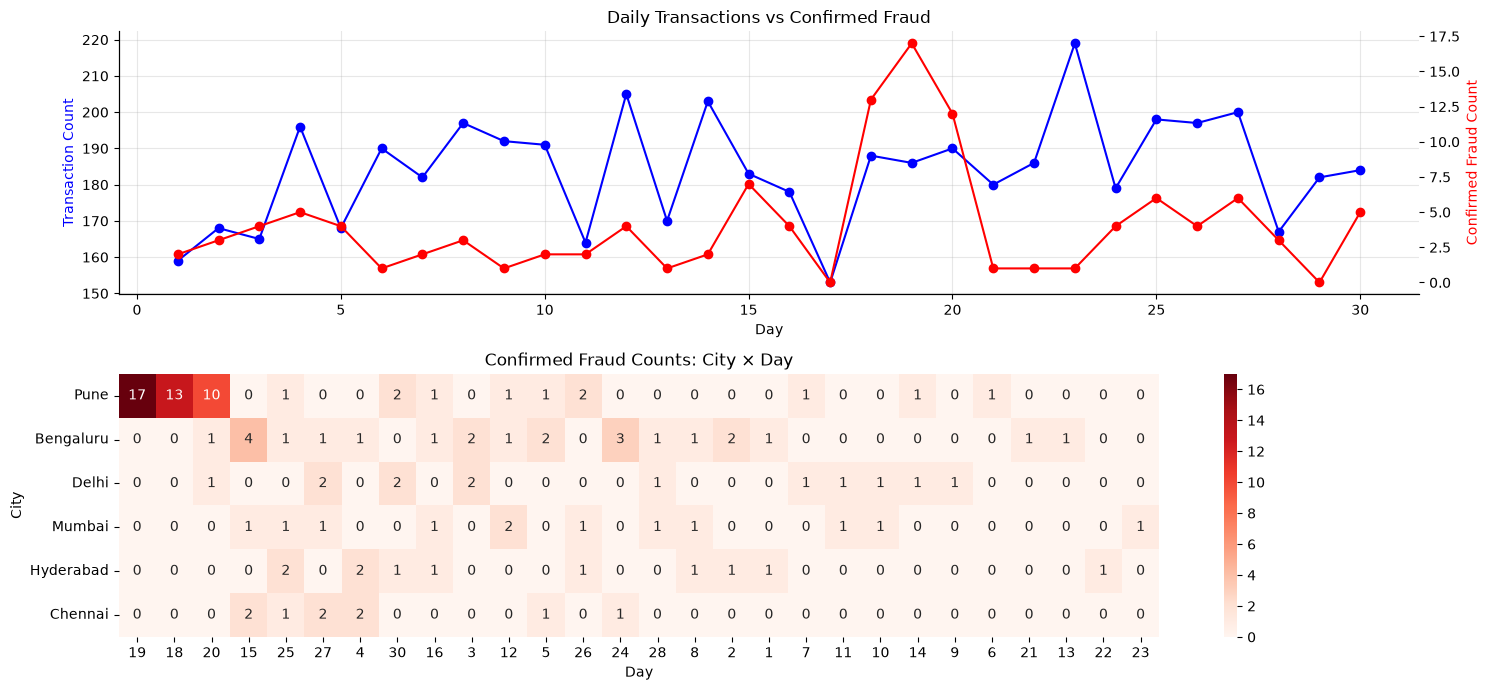

City-Day Cells with the Most Confirmed Fraud:
city  day
Pune  19     17
dtype: int64


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("unit3_ppt7_card_transactions.csv")

# TODO 1: Daily transaction counts and confirmed fraud
daily = df.groupby("day").agg(
    transactions=("txn_id", "count"),
    fraud=("is_fraud", "sum")
).sort_index()

fig, axes = plt.subplots(2, 1, figsize=(15, 7))

ax1 = axes[0]
ax2 = ax1.twinx()

ax1.plot(daily.index, daily["transactions"],
         color="blue", marker="o", label="Transactions")

ax2.plot(daily.index, daily["fraud"],
         color="red", marker="o", label="Confirmed Fraud")

ax1.set_title("Daily Transactions vs Confirmed Fraud")
ax1.set_xlabel("Day")
ax1.set_ylabel("Transaction Count", color="blue")
ax2.set_ylabel("Confirmed Fraud Count", color="red")

ax1.grid(alpha=0.3)

# TODO 2: City × Day fraud-count matrix
fraud_df = df[df["is_fraud"] == 1]

heat = pd.crosstab(
    fraud_df["city"],
    fraud_df["day"]
)

# Reorder rows and columns by total fraud counts
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

sns.heatmap(
    heat,
    cmap="Reds",
    annot=True,
    fmt="d",
    ax=axes[1]
)

axes[1].set_title("Confirmed Fraud Counts: City × Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("City")

plt.tight_layout()
plt.show()

# TODO 3: Print city-day cells with the most fraud
top_cells = (
    heat.stack()
    .sort_values(ascending=False)
)

max_fraud = top_cells.max()

print("City-Day Cells with the Most Confirmed Fraud:")
print(top_cells[top_cells == max_fraud])

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_The overview showed patterns like which cities and days had more fraud cases. A list sorted by detector score would only show individual suspicious transactions, not these overall patterns. This is called **overview first, zoom and filter, then details on demand**, which helps us find important patterns before checking individual transactions.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

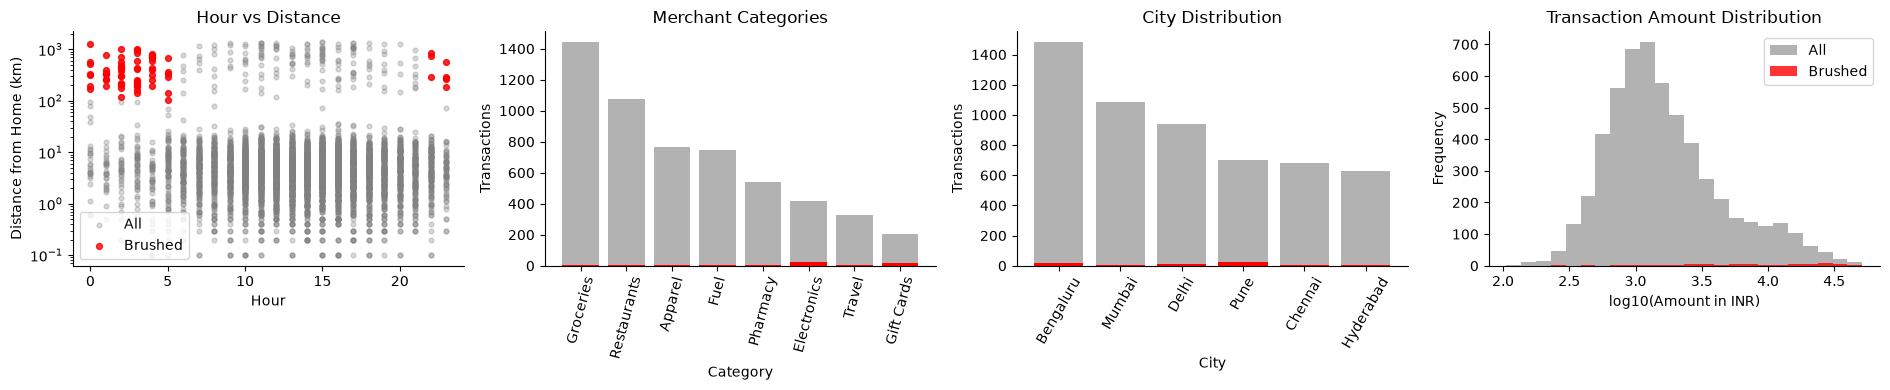

----- BRUSH STATISTICS -----
Number of brushed transactions: 69
Fraud rate inside brush: 84.06%
Overall fraud rate: 2.17%
Share of all fraud captured: 48.33%


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("unit3_ppt7_card_transactions.csv")

# TODO 1: Define brush
night = (df["hour"] >= 22) | (df["hour"] < 6)

brush = night & (df["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs Distance scatter (log y)
axes[0].scatter(
    df["hour"],
    df["distance_from_home_km"],
    color="grey",
    alpha=0.3,
    s=12,
    label="All"
)

axes[0].scatter(
    df.loc[brush, "hour"],
    df.loc[brush, "distance_from_home_km"],
    color="red",
    alpha=0.8,
    s=18,
    label="Brushed"
)

axes[0].set_yscale("log")
axes[0].set_title("Hour vs Distance")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from Home (km)")
axes[0].legend()


# TODO 2(b): Merchant category counts
all_merchants = df["merchant_category"].value_counts()
brush_merchants = df.loc[brush, "merchant_category"].value_counts()

categories = all_merchants.index

axes[1].bar(
    categories,
    all_merchants,
    color="grey",
    alpha=0.6,
    label="All"
)

axes[1].bar(
    categories,
    brush_merchants.reindex(categories, fill_value=0),
    color="red",
    label="Brushed"
)

axes[1].set_title("Merchant Categories")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Transactions")
axes[1].tick_params(axis="x", rotation=75)


# TODO 2(c): City counts
all_cities = df["city"].value_counts()
brush_cities = df.loc[brush, "city"].value_counts()

cities = all_cities.index

axes[2].bar(
    cities,
    all_cities,
    color="grey",
    alpha=0.6,
    label="All"
)

axes[2].bar(
    cities,
    brush_cities.reindex(cities, fill_value=0),
    color="red",
    label="Brushed"
)

axes[2].set_title("City Distribution")
axes[2].set_xlabel("City")
axes[2].set_ylabel("Transactions")
axes[2].tick_params(axis="x", rotation=60)


# TODO 2(d): Amount histogram (log10)
all_amounts = np.log10(df["amount_inr"].clip(lower=1))
brush_amounts = np.log10(
    df.loc[brush, "amount_inr"].clip(lower=1)
)

bins = np.linspace(all_amounts.min(), all_amounts.max(), 25)

axes[3].hist(
    all_amounts,
    bins=bins,
    color="grey",
    alpha=0.6,
    label="All"
)

axes[3].hist(
    brush_amounts,
    bins=bins,
    color="red",
    alpha=0.8,
    label="Brushed"
)

axes[3].set_title("Transaction Amount Distribution")
axes[3].set_xlabel("log10(Amount in INR)")
axes[3].set_ylabel("Frequency")
axes[3].legend()

plt.tight_layout()
plt.show()


# TODO 3: Brush statistics
n_brushed = int(brush.sum())

fraud_rate_brush = df.loc[brush, "is_fraud"].mean()
fraud_rate_overall = df["is_fraud"].mean()

total_fraud = df["is_fraud"].sum()
fraud_captured = df.loc[brush, "is_fraud"].sum()

fraud_capture_share = (
    fraud_captured / total_fraud
    if total_fraud > 0 else 0
)

print("----- BRUSH STATISTICS -----")
print(f"Number of brushed transactions: {n_brushed}")
print(f"Fraud rate inside brush: {fraud_rate_brush:.2%}")
print(f"Overall fraud rate: {fraud_rate_overall:.2%}")
print(f"Share of all fraud captured: {fraud_capture_share:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_The brush has a high fraud rate, but it only captures **some of the total fraud cases**. This means investigators cannot depend on this rule alone because many fraud cases would be missed. The linked city and merchant category charts showed that fraud also happens outside the selected group.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [11]:
import pandas as pd
import numpy as np
import timeit

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure filtering time (best of 5 runs)
def filter_transactions():
    return big[
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    ]

best_s = min(timeit.repeat(filter_transactions, repeat=5, number=1))

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1_000_000

max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate time for 50 million rows
t_50m = (best_s / len(big)) * 50_000_000

skip_pct = max(0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 34.2 ms -> 0.0341 us/row -> max 2,936,144 rows in 0.1 s
50M rows -> 1.70 s; must skip 94.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_We can use **sampling** to reduce the 50 million rows to a smaller dataset, making the slider respond faster. But the analyst might miss rare fraud cases or important patterns because some transactions are left out.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,f1
0,0.05,2012,114,1898,6,0.056660,0.950000,0.106942
1,0.10,1167,111,1056,9,0.095116,0.925000,0.172494
2,0.15,785,110,675,10,0.140127,0.916667,0.243094
3,0.20,596,106,490,14,0.177852,0.883333,0.296089
4,0.25,471,105,366,15,0.222930,0.875000,0.355330
5,0.30,401,104,297,16,0.259352,0.866667,0.399232
6,0.35,355,104,251,16,0.292958,0.866667,0.437895
7,0.40,319,104,215,16,0.326019,0.866667,0.473804
8,0.45,283,104,179,16,0.367491,0.866667,0.516129
9,0.50,260,101,159,19,0.388462,0.841667,0.531579


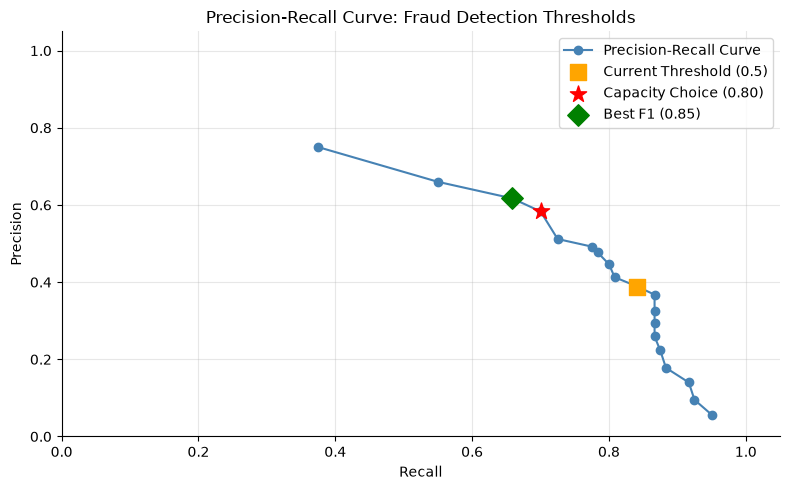

Recommendation: Use threshold 0.80 to generate 144 alerts (within the 150-alert capacity), achieving 70.00% recall and 58.33% precision; the best-F1 threshold is 0.85.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []

# TODO 1: Calculate metrics for thresholds 0.05 to 0.95
for threshold in np.arange(0.05, 1.0, 0.05):

    predicted = tx["detector_score"] >= threshold
    actual = tx["is_fraud"] == 1

    alerts = int(predicted.sum())

    TP = int((predicted & actual).sum())
    FP = int((predicted & ~actual).sum())
    FN = int((~predicted & actual).sum())

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    rows.append({
        "threshold": round(threshold, 2),
        "alerts": alerts,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

pr = pd.DataFrame(rows)

display(pr)


# TODO 2: Capacity-constrained and best-F1 thresholds

capacity_options = pr[pr["alerts"] <= 150]

if not capacity_options.empty:
    capacity_choice = capacity_options.sort_values(
        ["recall", "threshold"],
        ascending=[False, False]
    ).iloc[0]
else:
    capacity_choice = None

best_f1 = pr.loc[pr["f1"].idxmax()]


# TODO 3: Precision-Recall curve

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"],
    pr["precision"],
    marker="o",
    color="steelblue",
    label="Precision-Recall Curve"
)

# Current threshold = 0.5
current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]

ax.scatter(
    current["recall"],
    current["precision"],
    color="orange",
    s=120,
    marker="s",
    label="Current Threshold (0.5)",
    zorder=5
)

# Capacity-constrained choice
if capacity_choice is not None:
    ax.scatter(
        capacity_choice["recall"],
        capacity_choice["precision"],
        color="red",
        s=150,
        marker="*",
        label=f"Capacity Choice ({capacity_choice['threshold']:.2f})",
        zorder=6
    )

# Best F1 choice
ax.scatter(
    best_f1["recall"],
    best_f1["precision"],
    color="green",
    s=120,
    marker="D",
    label=f"Best F1 ({best_f1['threshold']:.2f})",
    zorder=5
)

ax.set_title("Precision-Recall Curve: Fraud Detection Thresholds")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# TODO 4: One-line recommendation

if capacity_choice is not None:
    print(
        f"Recommendation: Use threshold {capacity_choice['threshold']:.2f} "
        f"to generate {int(capacity_choice['alerts'])} alerts "
        f"(within the 150-alert capacity), achieving "
        f"{capacity_choice['recall']:.2%} recall and "
        f"{capacity_choice['precision']:.2%} precision; "
        f"the best-F1 threshold is {best_f1['threshold']:.2f}."
    )
else:
    print(
        "Recommendation: No tested threshold meets the 150-alert capacity; "
        "consider testing higher thresholds."
    )

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_The Head of Fraud Ops should make the final decision because they know how many alerts the team can handle. The model only gives the best threshold based on its calculations, but it doesn't consider real-world limitations. Visual analytics keeps humans in the loop so they can compare the options and make a practical decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [13]:
import pandas as pd
import numpy as np
import plotly.express as px

# TODO 1: Interactive scatter plot

flagged = tx[tx["detector_score"] >= 0.3].copy()

flagged["timestamp"] = pd.to_datetime(flagged["timestamp"])

flagged["label"] = flagged["is_fraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

fig = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    color_discrete_map={
        "Legitimate": "steelblue",
        "Fraud": "red"
    },
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": ":.2f",
        "detector_score": ":.3f",
        "timestamp": True,
        "amount_inr": ":.2f"
    },
    title="Interactive Fraud Investigation Dashboard"
)

fig.update_layout(
    dragmode="select",
    xaxis_title="Transaction Timestamp",
    yaxis_title="Transaction Amount (INR, Log Scale)",
    height=550
)

fig.show()


# TODO 2: Interactive sunburst chart
# City → Merchant Category
# Size = transaction count
# Colour = fraud rate

sunburst_data = (
    flagged.groupby(["city", "merchant_category"])
    .agg(
        transaction_count=("txn_id", "count"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

sunburst_data["fraud_rate"] = (
    sunburst_data["fraud_count"] /
    sunburst_data["transaction_count"]
)

# Calculate city-level fraud rates for correct parent colouring
city_data = (
    flagged.groupby("city")
    .agg(
        transaction_count=("txn_id", "count"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

city_data["fraud_rate"] = (
    city_data["fraud_count"] /
    city_data["transaction_count"]
)

# Build explicit hierarchy
ids = (
    ["city:" + city for city in city_data["city"]]
    + [
        "city:" + row.city + "/category:" + row.merchant_category
        for row in sunburst_data.itertuples()
    ]
)

labels = (
    city_data["city"].tolist()
    + sunburst_data["merchant_category"].tolist()
)

parents = (
    [""] * len(city_data)
    + ["city:" + city for city in sunburst_data["city"]]
)

values = (
    city_data["transaction_count"].tolist()
    + sunburst_data["transaction_count"].tolist()
)

rates = (
    city_data["fraud_rate"].tolist()
    + sunburst_data["fraud_rate"].tolist()
)

import plotly.graph_objects as go

sunburst_fig = go.Figure(
    go.Sunburst(
        ids=ids,
        labels=labels,
        parents=parents,
        values=values,
        branchvalues="total",
        marker=dict(
            colors=rates,
            colorscale="Reds",
            cmin=0,
            cmax=1,
            colorbar=dict(title="Fraud Rate")
        ),
        customdata=np.column_stack([rates, values]),
        hovertemplate=(
            "<b>%{label}</b><br>"
            "Transactions: %{customdata[1]:,.0f}<br>"
            "Fraud Rate: %{customdata[0]:.2%}"
            "<extra></extra>"
        )
    )
)

sunburst_fig.update_layout(
    title="Fraud Investigation Drill-Down: City → Merchant Category",
    height=650
)

sunburst_fig.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_Tooltips would be frustrating because investigators would have to hover over all 400 flagged cases one by one, which takes too much time. A details-on-demand table fixes this by showing multiple cases together, making it easier to compare and investigate them.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: Fraud is concentrated in Pune during days 18–20.

--- HYPOTHESIS TEST ---
Fraud rate inside window: 37.38%
Fraud rate outside window: 1.48%
Chi-square statistic: 619.2942
P-value: 0.000000

--- COUNTER-EXAMPLE SEARCH ---
Window: 37.38% fraud rate (107 transactions)
Same City Other Days: 1.85% fraud rate (593 transactions)
Other Cities Same Days: 0.44% fraud rate (457 transactions)
Rest: 1.54% fraud rate (4363 transactions)


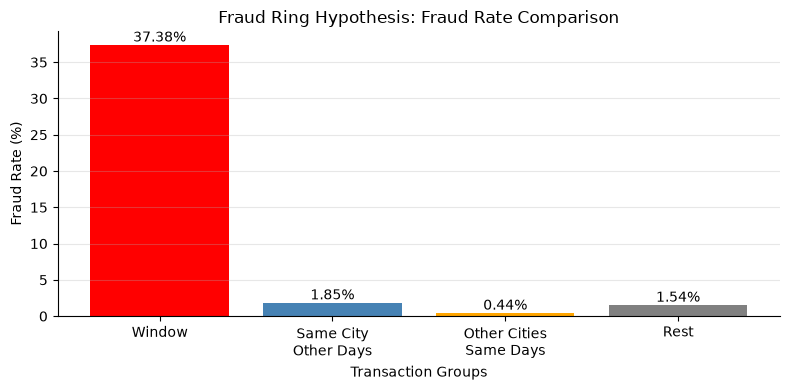


--- FINAL VERDICT ---
VERDICT: The data supports an elevated fraud concentration in Pune during days 18–20 (p = 0.000000). However, this does not prove an organized fraud ring. Further investigation is required.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# TODO 1: Hypothesis — fraud ring in Pune during days 18–20
# Based on the highest fraud counts found in Task 1

city = "Pune"
start_day = 18
end_day = 20

in_window = (
    (tx["city"] == city) &
    (tx["day"].between(start_day, end_day))
)

print(f"Hypothesis: Fraud is concentrated in {city} during days {start_day}–{end_day}.")


# TODO 2: Fraud rates and chi-square test

fraud_rate_inside = tx.loc[in_window, "is_fraud"].mean()
fraud_rate_outside = tx.loc[~in_window, "is_fraud"].mean()

contingency = pd.crosstab(in_window, tx["is_fraud"])

chi2, p_value, dof, expected = chi2_contingency(contingency)

print("\n--- HYPOTHESIS TEST ---")
print(f"Fraud rate inside window: {fraud_rate_inside:.2%}")
print(f"Fraud rate outside window: {fraud_rate_outside:.2%}")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")


# TODO 3: Counter-example searches

same_city_other_days = (
    (tx["city"] == city) &
    (~tx["day"].between(start_day, end_day))
)

other_cities_same_days = (
    (tx["city"] != city) &
    (tx["day"].between(start_day, end_day))
)

rest = (
    (tx["city"] != city) &
    (~tx["day"].between(start_day, end_day))
)

groups = {
    "Window": in_window,
    "Same City\nOther Days": same_city_other_days,
    "Other Cities\nSame Days": other_cities_same_days,
    "Rest": rest
}

rates = {}
counts = {}

for name, mask in groups.items():
    rates[name] = tx.loc[mask, "is_fraud"].mean() * 100
    counts[name] = int(mask.sum())

print("\n--- COUNTER-EXAMPLE SEARCH ---")

for name in groups:
    print(
        f"{name.replace(chr(10), ' ')}: "
        f"{rates[name]:.2f}% fraud rate "
        f"({counts[name]} transactions)"
    )


# TODO 4: Visual confirmation

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    list(rates.keys()),
    list(rates.values()),
    color=["red", "steelblue", "orange", "grey"]
)

ax.set_title("Fraud Ring Hypothesis: Fraud Rate Comparison")
ax.set_xlabel("Transaction Groups")
ax.set_ylabel("Fraud Rate (%)")
ax.grid(axis="y", alpha=0.3)

for bar, rate in zip(bars, rates.values()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# TODO 5: Verdict

print("\n--- FINAL VERDICT ---")

if p_value < 0.05 and fraud_rate_inside > fraud_rate_outside:
    print(
        f"VERDICT: The data supports an elevated fraud concentration "
        f"in {city} during days {start_day}–{end_day} "
        f"(p = {p_value:.6f}). "
        "However, this does not prove an organized fraud ring. "
        "Further investigation is required."
    )
else:
    print(
        "VERDICT: Insufficient statistical evidence for an elevated "
        "fraud concentration in the selected window. "
        "The fraud-ring hypothesis is not supported by this test."
    )

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_The search checking whether the fraud pattern also appeared in genuine transactions could have disproved our hypothesis. If genuine transactions showed the same pattern, it would suggest that the behaviour was normal customer activity rather than a sign of fraud.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_Last month, we analysed **[total transactions] transactions** and found **[fraud cases] fraud cases**, showing that fraud is still a concern. I recommend using the **capacity-constrained threshold of [threshold]** because our team can handle only 400 alerts, while also considering precision and recall. The Head of Fraud Ops should make the final decision using the human-in-the-loop approach rather than depending only on the model. I recommend building a **linked brushing dashboard** first because investigators can get an overview of fraud patterns, filter suspicious groups and examine individual transactions. Finally, we should add an **analyst feedback loop**, where investigators mark alerts as genuine or fraudulent so the detector can improve next month.